# Annual knowledge extent and publication growth in psychology, 2001–2024

All 240,000 pool papers (10,000 random psychology journal articles with abstracts per year) are now embedded with SPECTER2 proximity (`src/embed_pool.py`), and the papers excluded at the KE step are fixed (`src/ke_eligibility.py`). This notebook computes the project's first outcome, the yearly **knowledge extent (KE)** of psychology, and compares it with the yearly number of journal articles:

1. **Yearly KE.** 1,000 draws of 1,000 papers per year. In each draw, KE is the largest distance from a paper to the draw's centroid (Hao et al., 2026).
2. **KE and output over time.** Both series, both relative to 2001, and the whole-period elasticity.
3. **The count–KE scatter.** Year-to-year growth in output against the year-to-year change in KE.
4. **Which papers set the maximum,** read paper by paper.
5. **Robustness.** The 95th-percentile distance, which reflects the bulk of each draw rather than its single farthest paper.
6. **Sanity check.** KE with the largest subfield removed, against the same number of papers removed at random.
7. **Maps of the space.** One KE draw from 2001 and one from 2024, on a t-SNE map as in Hao et al. (2026), and with their centroids aligned to show exact distances.

All settings (seed, draws, summaries, figures, regression) were written into the decision log on 2026-11-22, before any KE value was computed. One check in Section 5 and one diagnostic in Section 7 were added after seeing the results and are labelled as such.

## Literature Review

The question here is whether the semantic breadth of a field grows with its output. Three studies shaped how I set up the comparison.

Milojević (2015) measured the *cognitive extent* of a literature as the number of distinct phrases in titles, counted in fixed batches of 10,000 phrases (about 3,000 titles), so that a larger year does not score higher simply because it contains more text. Across about 20 million articles in physics, astronomy and biomedicine, cognitive extent did not track publication growth: breadth did not shrink when output fell fivefold during the Second World War, and it grew fastest in the 1970s, when output was flat. KE follows the same logic. Every year is measured on draws of exactly 1,000 papers, so a year cannot reach farther just because it has more papers, and the comparison with output is made explicitly, through the elasticity of KE with respect to the number of articles.

Bérubé et al. (2018) show what happens without that control. Across 31.6 million Web of Science titles from 1975 to 2014, the type–token ratio of title words fell by 57%, mostly because the corpus grew, and measures based on the tail of the word distribution were the least sensitive to corpus size. The concentration of title words rose by 7.97% across all fields but fell by 11.7% in psychology, so psychology is a field where breadth need not have narrowed. Two lessons carry over. A diversity measure computed on a growing corpus mixes size with breadth, which is why KE is never computed on whole years. And a measure set by extremes, such as KE's maximum distance, needs a companion that reflects the bulk of the distribution, which is why I also report the 95th-percentile distance.

Chu and Evans (2021) suggest the opposite expectation. Measuring field size as papers per field per year, the same quantity as my N_t, they find that attention in larger fields concentrates on established work: the year-to-year rank correlation of the 50 most-cited papers rises from 0.25 to 0.74 between fields publishing 1,000 and 100,000 papers a year, and the share of disruptive papers falls from 49% to 13%. If growth crowds attention onto a canon, the semantic reach of a typical sample of papers might narrow as output grows, which would show up as a negative elasticity. Their measure is built from citations, not text, so it motivates the question rather than predicting the size of the answer.

**References**

- Bérubé, N., Sainte-Marie, M. H., Mongeon, P., & Larivière, V. (2018). Words by the tail: Assessing lexical diversity in scholarly titles using frequency-rank distribution tail fits. *PLoS ONE*, 13(7), e0197775. https://doi.org/10.1371/journal.pone.0197775
- Chu, J. S. G., & Evans, J. A. (2021). Slowed canonical progress in large fields of science. *PNAS*, 118(41), e2021636118. https://doi.org/10.1073/pnas.2021636118
- Hao, Q., Xu, F., Li, Y., & Evans, J. A. (2026). Artificial intelligence tools expand scientists' impact but contract science's focus. *Nature*, 649(8099), 1237–1243. https://doi.org/10.1038/s41586-025-09922-y
- Milojević, S. (2015). Quantifying the cognitive extent of science. *Journal of Informetrics*, 9(4), 962–973. https://doi.org/10.1016/j.joi.2015.10.005

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Circle
import numpy as np
import pandas as pd
from sklearn.manifold import TSNE

from src import knowledge_extent as ke   # draws, summaries, elasticity, first differences

POOL = Path("data/pool/psychology_field32/pool.parquet")
COUNTS = Path("data/counts/psychology_field32/yearly_counts.csv")
ELIGIBILITY = Path("data/ke/psychology_field32/eligibility.parquet")
ELIGIBILITY_REPORT = Path("data/ke/psychology_field32/eligibility_report.csv")
EMBEDDINGS = Path("data/embeddings/specter2_proximity")
DRAWS = Path("data/ke/psychology_field32/ke_draws_specter2_proximity.parquet")
DRAWS_NO_JVIS = Path("data/ke/psychology_field32/ke_draws_specter2_proximity_no_jvis.parquet")
TABLES, FIGURES = Path("outputs/tables"), Path("outputs/figures")
for folder in (TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)
YEARS = np.arange(2001, 2025)
pd.set_option("display.max_colwidth", 90)

# chart style (as in Week 2): thin lines, recessive grid, text in ink colors (not series colors)
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"   # palette validated for color-vision deficiency
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

def style_axes(ax):
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED)

def label_end(ax, x, y, text, color=INK):
    ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points", va="center", color=color, fontsize=9)

## 1. Inputs

**Publication count.** N_t is the number of psychology journal articles in year *t*: OpenAlex works whose primary topic is in field 32, of type article, in English, not paratext, in a journal, in the core corpus (pulled 2026-10-25). The count of those with abstracts is shown beside it, so that growing abstract coverage is not mistaken for growing output.

**Papers for KE.** Each year's pool of 10,000 random journal articles with abstracts, minus the papers excluded at the KE step (decision log, 2026-11-21): no title, duplicate records, placeholder ("boilerplate") abstracts shared by papers with different titles, and abstracts under 200 characters.

In [2]:
counts = pd.read_csv(COUNTS).set_index("year").loc[2001:2024]
N = counts["journal_articles"]                     # N_t
N_abstract = counts["journal_articles_abstract"]
eligibility = pd.read_parquet(ELIGIBILITY)
pool = pd.read_parquet(POOL, columns=["openalex_id", "title", "source_name", "doi"])
assert (pool["openalex_id"].to_numpy() == eligibility["openalex_id"].to_numpy()).all()  # same order
eligible_report = pd.read_csv(ELIGIBILITY_REPORT).set_index("year")

inputs = pd.DataFrame({"journal articles (N_t)": N, "with abstracts": N_abstract,
                       "share with abstracts": (N_abstract / N).round(3),
                       "pool": eligible_report["pool"], "KE-eligible": eligible_report["eligible"]})
print(f"N_t: {N.iloc[0]:,} (2001) to {N.iloc[-1]:,} (2024), {N.iloc[-1] / N.iloc[0]:.1f}x; "
      f"with abstracts: {N_abstract.iloc[0]:,} to {N_abstract.iloc[-1]:,}, {N_abstract.iloc[-1] / N_abstract.iloc[0]:.1f}x")
print(f"KE-eligible papers per year: {inputs['KE-eligible'].min():,} to {inputs['KE-eligible'].max():,}")
inputs

N_t: 29,631 (2001) to 148,359 (2024), 5.0x; with abstracts: 18,230 to 129,120, 7.1x
KE-eligible papers per year: 9,301 to 9,829


,journal articles (N_t),with abstracts,share with abstracts,pool,KE-eligible
year,,,,,
2001,29631,18230,0.615,10000,9301
2002,32086,19749,0.616,10000,9342
2003,33884,20799,0.614,10000,9368
2004,36056,22907,0.635,10000,9409
2005,39381,24954,0.634,10000,9443
2006,44802,28548,0.637,10000,9526
2007,47799,30879,0.646,10000,9516
2008,52756,34776,0.659,10000,9536
2009,56630,37795,0.667,10000,9564


Output grew from 29,631 journal articles in 2001 to 148,359 in 2024, 5.0 times as many, and fell in only one year (2022). Because the share with abstracts rose from 62% to 87%, the with-abstract count grew faster (7.1×), which is why N_t counts all journal articles. After the exclusions, each year has 9,301 to 9,829 KE-eligible papers, more than nine times the 1,000-paper draw.

## 2. Yearly knowledge extent

For a draw *S* of 1,000 papers with embedding vectors $x_i$, the centroid is $c_S = \frac{1}{1000}\sum_{i \in S} x_i$ and

$$\mathrm{KE}(S) = \max_{i \in S} \lVert x_i - c_S \rVert ,$$

the Euclidean distance from the draw's centroid to its farthest paper. Each year gets 1,000 draws of 1,000 distinct eligible papers (`numpy.random.default_rng([20261122, year])`), and the year's KE is the **median** over its draws. Because every draw has exactly 1,000 papers, a year with more papers does not reach farther just by having more chances at an outlier. The spread of the 1,000 draw values describes sampling variation *within* a year. It is not a confidence interval, and the draws are not observations for the growth–KE relationship: each year contributes one median.

The same draws also give the 95th-percentile distance (Section 6). The first run takes about a minute; later runs read the saved draws.

In [3]:
draws = ke.field_draws(EMBEDDINGS, eligibility, YEARS, output=DRAWS, l2=False)   # raw vectors only
summary = ke.summarize(draws).set_index("year")
summary.assign(journal_articles=N, journal_articles_abstract=N_abstract).to_csv(TABLES / "field_ke_ke_by_year.csv")

table = summary[["eligible", "ke_max_median", "ke_max_q1", "ke_max_q3", "ke_max_p2.5", "ke_max_p97.5"]].copy()
table.columns = ["eligible papers", "median KE", "25th pct", "75th pct", "2.5th pct", "97.5th pct"]
print(f"{len(draws):,} draws ({draws['year'].nunique()} years x {ke.N_DRAWS:,} draws of {ke.DRAW_SIZE:,} papers)")
table.round(3)

24,000 draws (24 years x 1,000 draws of 1,000 papers)


,eligible papers,median KE,25th pct,75th pct,2.5th pct,97.5th pct
year,,,,,,
2001,9301,11.957,11.743,12.119,11.571,12.289
2002,9342,11.965,11.786,12.175,11.536,12.542
2003,9368,11.928,11.796,11.999,11.571,12.078
2004,9409,11.840,11.655,12.169,11.454,12.552
2005,9443,11.891,11.734,12.078,11.529,12.208
2006,9526,11.952,11.761,12.170,11.530,12.511
2007,9516,12.038,11.849,12.197,11.488,12.454
2008,9536,12.177,12.091,12.289,11.724,12.610
2009,9564,11.895,11.728,12.274,11.447,13.027


Median KE ranges from 11.71 (2021) to 12.37 (2018). In most years the middle half of the draws spans 0.2 to 0.6 distance units, but in 2016–2018 it spans 1.0 to 1.3, a sign that a few papers far from the rest enter some draws and not others. Section 4 identifies them.

## 3. KE and publication count over time

The two series have different units, so they are shown in two panels with a shared time axis rather than on two y-axes.

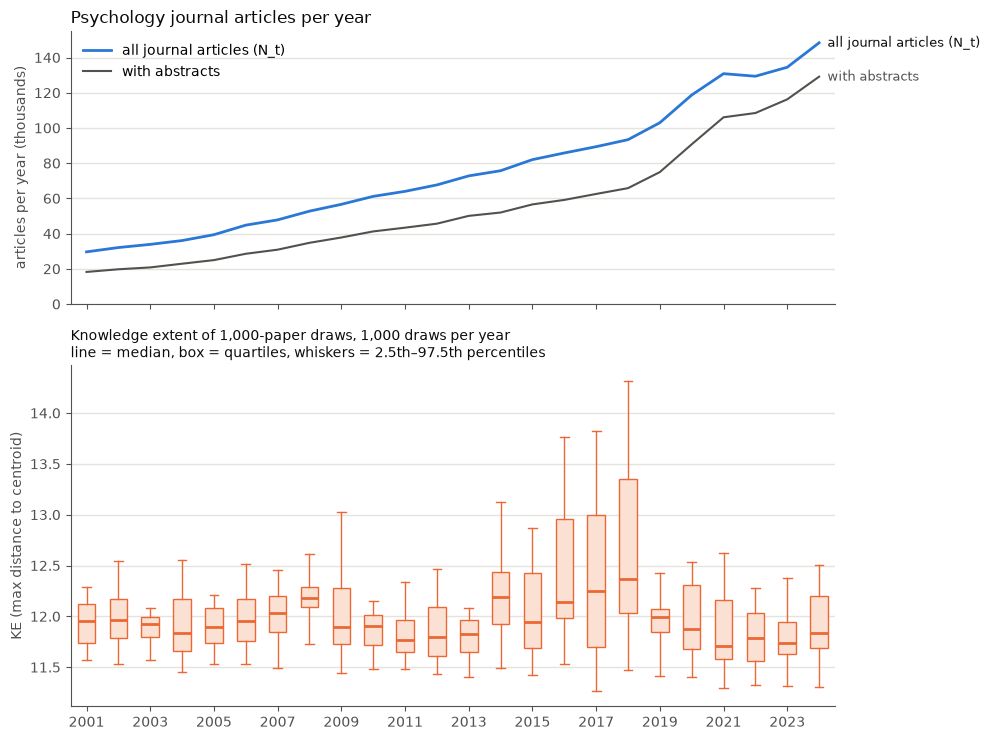

In [4]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.25]})
top.plot(YEARS, N / 1000, color=BLUE, lw=2, label="all journal articles (N_t)")
top.plot(YEARS, N_abstract / 1000, color=MUTED, lw=1.5, label="with abstracts")
label_end(top, YEARS[-1], N.iloc[-1] / 1000, "all journal articles (N_t)")
label_end(top, YEARS[-1], N_abstract.iloc[-1] / 1000, "with abstracts", MUTED)
top.set_ylim(0, None)
top.set_ylabel("articles per year (thousands)", color=MUTED)
top.set_title("Psychology journal articles per year", loc="left", color=INK)
top.legend(frameon=False, loc="upper left")
style_axes(top)

bottom.boxplot([draws.loc[draws["year"] == y, "ke_max"] for y in YEARS], positions=YEARS, widths=0.55,
               whis=(2.5, 97.5), showfliers=False, patch_artist=True,
               boxprops={"facecolor": "#fbe1d4", "edgecolor": ORANGE, "linewidth": 1},
               medianprops={"color": ORANGE, "linewidth": 2},
               whiskerprops={"color": ORANGE, "linewidth": 1}, capprops={"color": ORANGE, "linewidth": 1})
bottom.set_ylabel("KE (max distance to centroid)", color=MUTED)
bottom.set_title("Knowledge extent of 1,000-paper draws, 1,000 draws per year\n"
                 "line = median, box = quartiles, whiskers = 2.5th–97.5th percentiles", loc="left", color=INK, fontsize=10)
bottom.set_xticks(YEARS[::2], [str(y) for y in YEARS[::2]])
style_axes(bottom)
fig.tight_layout()
fig.savefig(FIGURES / "field_ke_counts_and_ke.png", dpi=200, bbox_inches="tight")
plt.show()

To compare the two as percentage changes, both are divided by their 2001 value and drawn on a log scale, where equal distances are equal ratios.

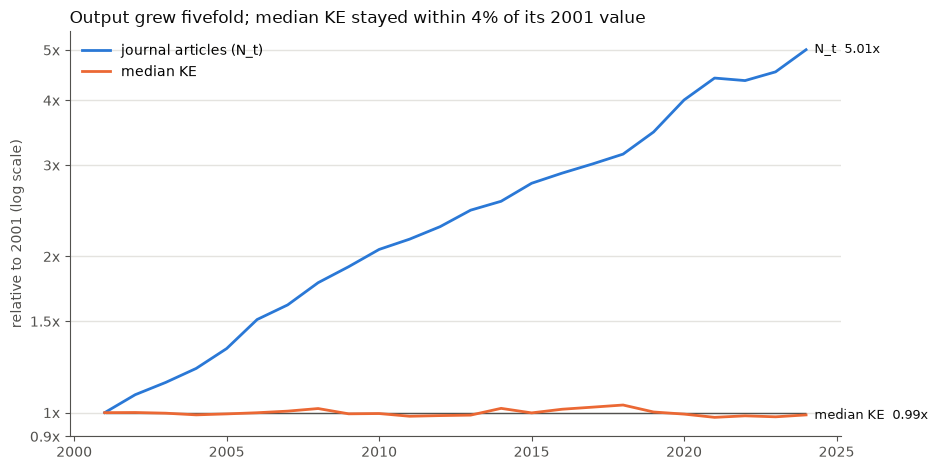

Mean N_t: 31,867 (2001–2003) -> 137,400 (2022–2024), 4.31x
Mean median KE: 11.950 -> 11.788, -1.4%
Whole-period elasticity: -0.009


In [5]:
relative = pd.DataFrame({"N_t": N / N.iloc[0], "median KE": summary["ke_max_median"] / summary["ke_max_median"].iloc[0]})
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.hlines(1, YEARS[0], YEARS[-1], color=MUTED, lw=1)
ax.plot(YEARS, relative["N_t"], color=BLUE, lw=2, label="journal articles (N_t)")
ax.plot(YEARS, relative["median KE"], color=ORANGE, lw=2, label="median KE")
label_end(ax, YEARS[-1], relative["N_t"].iloc[-1], f"N_t  {relative['N_t'].iloc[-1]:.2f}x")
label_end(ax, YEARS[-1], relative["median KE"].iloc[-1], f"median KE  {relative['median KE'].iloc[-1]:.2f}x")
ax.set_yscale("log")
ax.set_yticks([0.9, 1, 1.5, 2, 3, 4, 5])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}x"))
ax.yaxis.set_minor_locator(mticker.NullLocator())
ax.set_ylabel("relative to 2001 (log scale)", color=MUTED)
ax.set_title("Output grew fivefold; median KE stayed within 4% of its 2001 value", loc="left", color=INK)
ax.legend(frameon=False, loc="upper left")
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "field_ke_relative_to_2001.png", dpi=200, bbox_inches="tight")
plt.show()

whole = ke.elasticity(summary["ke_max_median"], N)
print(f"Mean N_t: {whole['n_early']:,.0f} ({whole['early']}) -> {whole['n_late']:,.0f} ({whole['late']}), {whole['n_growth']:.2f}x")
print(f"Mean median KE: {whole['ke_early']:.3f} -> {whole['ke_late']:.3f}, {whole['ke_change']:+.1%}")
print(f"Whole-period elasticity: {whole['elasticity']:.3f}")

Between 2001–03 and 2022–24, mean output grew 4.31-fold while mean median KE changed by −1.4%, a **whole-period elasticity of −0.01**. An elasticity of 1 would mean KE grew as fast as output; 0 means the extra papers were "more of the same". Psychology is close to 0. Output grew fivefold, but a 1,000-paper sample from 2024 reaches about as far from its centre as one from 2001. The yearly medians move by up to 3.5% around that flat line without a trend, and the largest movements (2014–2018) are explained in Section 4.

## 4. The count–KE scatter

Plotting yearly KE against yearly output would show 24 points along a time path. Any two series that drift over time correlate in levels whether or not one affects the other, so the design uses **year-to-year changes** instead: Δlog N_t is a year's output growth (0.05 ≈ 5%), and Δlog KE_t is the change in its median KE. The slope of

$$\Delta \log \mathrm{KE}_t = \alpha + \beta\,\Delta \log N_t + \varepsilon_t$$

asks whether years of faster growth were also years of rising KE. With 23 year pairs, it is a descriptive check.

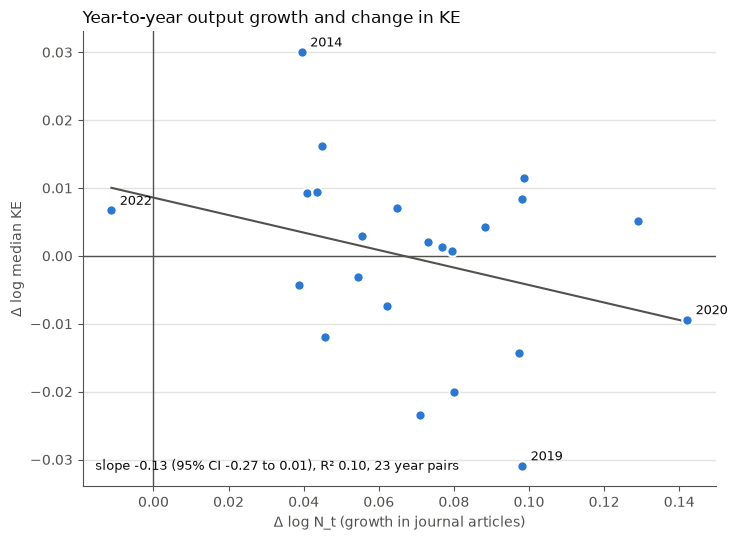

pairs           23.0000
alpha            0.0086
beta            -0.1288
beta_se_hc1      0.0715
beta_ci_low     -0.2688
beta_ci_high     0.0113
r_squared        0.0973
dtype: float64

In [6]:
changes, fit = ke.first_difference(summary["ke_max_median"], N)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(0, color=MUTED, lw=1)
ax.scatter(changes["d_log_n"], changes["d_log_ke"], s=56, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
x = np.linspace(changes["d_log_n"].min(), changes["d_log_n"].max(), 50)
ax.plot(x, fit["alpha"] + fit["beta"] * x, color=MUTED, lw=1.5)
for year in (2014, 2019, 2020, 2022):
    ax.annotate(str(year), (changes.loc[year, "d_log_n"], changes.loc[year, "d_log_ke"]),
                xytext=(6, 4), textcoords="offset points", color=INK, fontsize=9)
ax.text(0.02, 0.03, f"slope {fit['beta']:.2f} (95% CI {fit['beta_ci_low']:.2f} to {fit['beta_ci_high']:.2f}), "
        f"R² {fit['r_squared']:.2f}, {fit['pairs']} year pairs", transform=ax.transAxes, va="bottom", color=INK, fontsize=9)
ax.set_xlabel("Δ log N_t (growth in journal articles)", color=MUTED)
ax.set_ylabel("Δ log median KE", color=MUTED)
ax.set_title("Year-to-year output growth and change in KE", loc="left", color=INK)
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "field_ke_count_ke_scatter.png", dpi=200, bbox_inches="tight")
plt.show()
pd.Series(fit).round(4)

The slope is **−0.13** (95% CI −0.27 to 0.01, R² = 0.10): years of faster growth saw slightly smaller rises in KE, but the interval includes zero. The series also offers little to work with. In 18 of the 23 year pairs output grew by 4–10%, and the slope rests on a few points. The two most influential are 2014 (KE +3.0% in a year of 4% growth) and 2019 (KE −3.1% in a year of 10% growth), the first and last years of the episode explained in the next section. This is why the design estimates the growth–KE relationship with a panel of topics that grew at very different speeds, and keeps this regression as a description.

## 5. Which papers set the maximum?

KE is a maximum, so a year's value is set by its few farthest papers. For each draw I record which paper is farthest from the centroid, and then read the papers that do this most often.

In [7]:
info = pool.set_index("openalex_id")
draws["journal"] = draws["farthest_id"].map(info["source_name"])
share = draws.groupby("year")["farthest_id"].value_counts(normalize=True)
concentration = share.groupby(level="year").agg(top_paper=lambda s: s.iloc[0], top_three=lambda s: s.iloc[:3].sum(),
                                                papers_setting_max="size")
print("Share of a year's draws whose maximum is set by its most frequent farthest paper: "
      f"{concentration['top_paper'].min():.2f}-{concentration['top_paper'].max():.2f}; by the top three: "
      f"{concentration['top_three'].min():.2f}-{concentration['top_three'].max():.2f}; "
      f"different papers setting the maximum per year: {concentration['papers_setting_max'].min()}-{concentration['papers_setting_max'].max()}")

rows = []
for year in (2001, 2010, 2017, 2024):
    for openalex_id, value in share.loc[year].head(3).items():
        rows.append({"year": year, "share of draws": round(value, 2), "title": info.loc[openalex_id, "title"],
                     "journal": info.loc[openalex_id, "source_name"]})
pd.DataFrame(rows)

Share of a year's draws whose maximum is set by its most frequent farthest paper: 0.10-0.12; by the top three: 0.26-0.30; different papers setting the maximum per year: 45-54


,year,share of draws,title,journal
0,2001,0.11,Brightness and Color of Fluorescent Yellow and Fluorescent Yellow Green Retroreflectiv...,Transportation Research Record Journal of the Transportation Research Board
1,2001,0.09,Disrupted neural responses to phonological and orthographic processing in dyslexic chi...,Neuroreport
2,2001,0.09,Fecal analysis of ovarian cycles in female black‐handed spider monkeys (Ateles geoffroyi),American Journal of Primatology
3,2010,0.12,The Influence of Frequency and Semantic Similarity on How Children Learn Grammar,First Language
4,2010,0.10,Sleep Patterns in Obese Patients during Weight Reduction,Psychotherapy and Psychosomatics
5,2010,0.07,Haptic movements enhance visual motion aftereffect,Journal of Vision
6,2017,0.11,Eye Movements During Rapid Naming tasks Predict Reading Ability.,Journal of Vision
7,2017,0.10,Effects of Talking and Visual Attention Load on Driving Behavior,Journal of Vision
8,2017,0.09,How robust are color-specific biases in memory?,Journal of Vision
9,2024,0.10,Absence of eye position effects in the early auditory cortex of monkeys,Neuroreport


No single odd document drives a year. In every year the most frequent farthest paper sets the maximum in 10–12% of draws, which is about the chance that it is drawn at all (1,000 of about 9,600 papers), and 45 to 54 different papers set the maximum over a year's 1,000 draws. The farthest papers are real research at the edges of psychology: the colour of fluorescent traffic signs, primate endocrinology, sensory neuroscience, facial-expression recognition in computer vision. None is placeholder text, so the exclusion rules did their job.

One journal stands out, though.

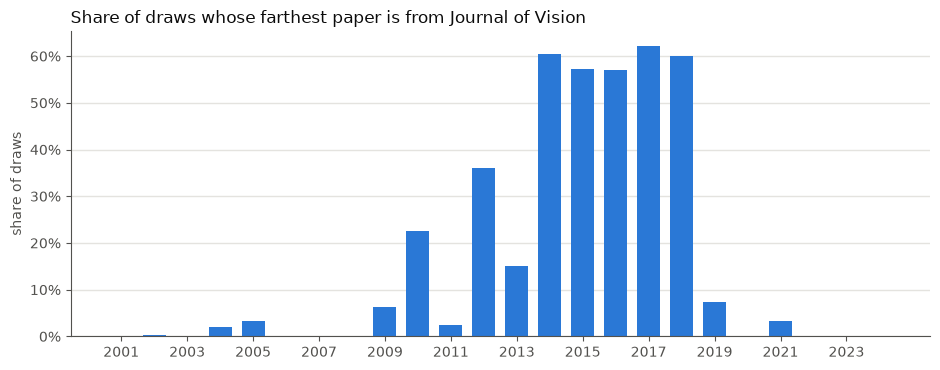

DOIs of the Journal of Vision papers that most often set the maximum, 2014-2018:
10.1167/16.12.370, 10.1167/17.10.539, 10.1167/15.12.1093, 10.1167/18.10.1336, 10.1167/14.10.443, 10.1167/17.10.971


,share of draws with a Journal of Vision maximum,Journal of Vision papers in the eligible pool
year,,
2001,0.000,0
2002,0.004,1
2003,0.000,0
2004,0.020,18
2005,0.034,17
2006,0.000,2
2007,0.000,2
2008,0.000,5
2009,0.062,4


In [8]:
draws["jvis"] = draws["journal"].eq("Journal of Vision")
eligible_pool = pool.assign(year=eligibility["publication_year"].to_numpy())[eligibility["ke_eligible"].to_numpy()]
jvis = pd.DataFrame({
    "share of draws with a Journal of Vision maximum": draws.groupby("year")["jvis"].mean().round(3),
    "Journal of Vision papers in the eligible pool": eligible_pool[eligible_pool["source_name"].eq("Journal of Vision")]
        .groupby("year").size().reindex(YEARS, fill_value=0)})

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.bar(YEARS, jvis.iloc[:, 0], width=0.7, color=BLUE)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_ylabel("share of draws", color=MUTED)
ax.set_title("Share of draws whose farthest paper is from Journal of Vision", loc="left", color=INK)
ax.set_xticks(YEARS[::2], [str(y) for y in YEARS[::2]])
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "field_ke_jvis_share.png", dpi=200, bbox_inches="tight")
plt.show()

top_jvis = draws.loc[draws["jvis"] & draws["year"].between(2014, 2018), "farthest_id"].value_counts().head(6).index
print("DOIs of the Journal of Vision papers that most often set the maximum, 2014-2018:")
print(", ".join(info.loc[top_jvis, "doi"].str.replace("https://doi.org/", "")))
jvis

From 2014 to 2018, a paper from *Journal of Vision* sets the maximum in 57–62% of draws, although the journal has only 9 to 23 of each year's ~9,600 eligible papers. All of the papers that do this most often come from the annual issue in which the journal publishes the abstracts of the Vision Sciences Society meeting (volume 14 issue 10, 15(12), 16(12), 17(10), 18(10), with article numbers above 1,000). A few of these vision-science meeting abstracts sit farther from psychology's centroid than any other paper in those years, and they produce the 2014–2018 rise in median KE in Section 3.

**A check added after seeing the results.** This check was not pre-specified (decision log, 2026-11-22). I recompute KE with the same seed and settings without the 365 *Journal of Vision* papers. The pre-specified series remains the main result.

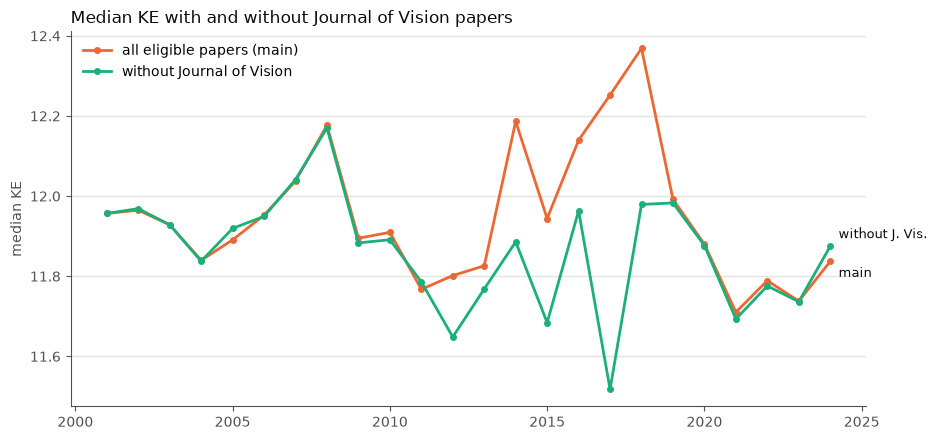

,main,without Journal of Vision
"KE change, 2001-03 to 2022-24",-1.4%,-1.3%
elasticity,-0.009,-0.009
first-difference slope,-0.129,-0.046
95% CI,-0.27 to 0.01,-0.21 to 0.12


In [9]:
no_jvis = eligibility.assign(ke_eligible=eligibility["ke_eligible"] & pool["source_name"].ne("Journal of Vision").to_numpy())
draws_no_jvis = ke.field_draws(EMBEDDINGS, no_jvis, YEARS, output=DRAWS_NO_JVIS, l2=False)
summary_no_jvis = ke.summarize(draws_no_jvis).set_index("year")

fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.plot(YEARS, summary["ke_max_median"], color=ORANGE, lw=2, marker="o", ms=4, label="all eligible papers (main)")
ax.plot(YEARS, summary_no_jvis["ke_max_median"], color=GREEN, lw=2, marker="o", ms=4, label="without Journal of Vision")
main_end, alt_end = summary["ke_max_median"].iloc[-1], summary_no_jvis["ke_max_median"].iloc[-1]
nudge = 0.03 if main_end >= alt_end else -0.03   # the line that ends higher gets the upper label
label_end(ax, YEARS[-1], main_end + nudge, "main")
label_end(ax, YEARS[-1], alt_end - nudge, "without J. Vis.")
ax.set_ylabel("median KE", color=MUTED)
ax.set_title("Median KE with and without Journal of Vision papers", loc="left", color=INK)
ax.legend(frameon=False, loc="upper left")
style_axes(ax)
fig.tight_layout()
fig.savefig(FIGURES / "field_ke_without_jvis.png", dpi=200, bbox_inches="tight")
plt.show()

check = {}
for name, series in (("main", summary["ke_max_median"]), ("without Journal of Vision", summary_no_jvis["ke_max_median"])):
    e, (_, f) = ke.elasticity(series, N), ke.first_difference(series, N)
    check[name] = {"KE change, 2001-03 to 2022-24": f"{e['ke_change']:+.1%}", "elasticity": round(e["elasticity"], 3),
                   "first-difference slope": round(f["beta"], 3),
                   "95% CI": f"{f['beta_ci_low']:.2f} to {f['beta_ci_high']:.2f}"}
pd.DataFrame(check)

Without *Journal of Vision*, the 2014–2018 rise mostly disappears, and the series stays within about 3% of 11.8 throughout. It still moves by up to 4% between adjacent years (2016 to 2018), a reminder that a year's maximum depends on the few most extreme papers in its single pool of 10,000. The whole-period elasticity does not change (−0.009 in both), because neither the 2001–03 nor the 2022–24 window contains such papers. The year-to-year slope does: it moves from −0.13 to −0.05 (95% CI −0.21 to 0.12). The slope in Section 4 was carried by this one episode, while the flat whole-period result does not depend on it. Whether meeting abstracts and conference proceedings should be excluded by a general rule (ICPhS proceedings also appear among the farthest papers) is a decision for later, to be made by source type rather than by its effect on KE.

## 6. Robustness: the 95th percentile

The maximum depends on a few papers. The **95th-percentile distance** of each draw reflects the outer part of the bulk instead. Both statistics come from the same draws.

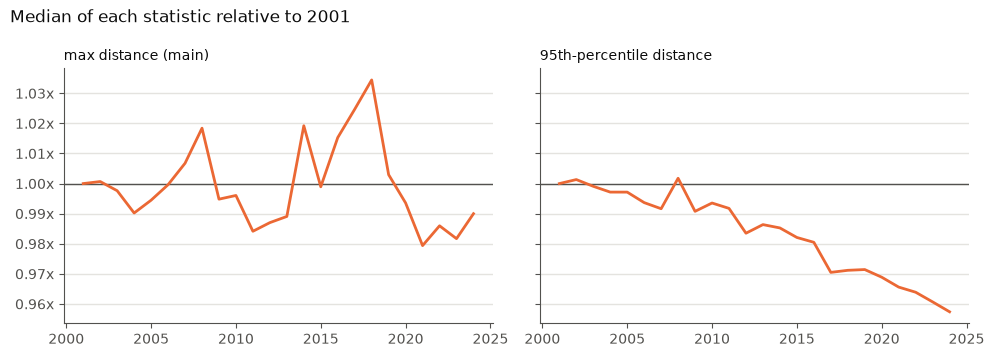

,2001,2024,"change, 2001-03 to 2022-24",elasticity,first-difference slope,CI low,CI high
max distance (main),11.957,11.837,-0.014,-0.009,-0.129,-0.269,0.011
95th-percentile distance,10.703,10.247,-0.039,-0.028,0.022,-0.022,0.066
"max distance, without Journal of Vision (post hoc)",11.957,11.875,-0.013,-0.009,-0.046,-0.208,0.115


In [10]:
labels = {"ke_max": "max distance (main)", "ke_p95": "95th-percentile distance"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (column, label) in zip(axes, labels.items()):
    series = summary[f"{column}_median"]
    ax.axhline(1, color=MUTED, lw=1)
    ax.plot(YEARS, series / series.iloc[0], color=ORANGE, lw=2)
    ax.set_title(label, loc="left", color=INK, fontsize=10)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.2f}x"))
    style_axes(ax)
fig.suptitle("Median of each statistic relative to 2001", x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig(FIGURES / "field_ke_robustness.png", dpi=200, bbox_inches="tight")
plt.show()

rows = {}
for column, label in labels.items():
    e, (_, f) = ke.elasticity(summary[f"{column}_median"], N), ke.first_difference(summary[f"{column}_median"], N)
    rows[label] = {"2001": summary[f"{column}_median"].iloc[0], "2024": summary[f"{column}_median"].iloc[-1],
                   "change, 2001-03 to 2022-24": e["ke_change"], "elasticity": e["elasticity"],
                   "first-difference slope": f["beta"], "CI low": f["beta_ci_low"], "CI high": f["beta_ci_high"]}
e, (_, f) = ke.elasticity(summary_no_jvis["ke_max_median"], N), ke.first_difference(summary_no_jvis["ke_max_median"], N)
rows["max distance, without Journal of Vision (post hoc)"] = {
    "2001": summary_no_jvis["ke_max_median"].iloc[0], "2024": summary_no_jvis["ke_max_median"].iloc[-1],
    "change, 2001-03 to 2022-24": e["ke_change"], "elasticity": e["elasticity"],
    "first-difference slope": f["beta"], "CI low": f["beta_ci_low"], "CI high": f["beta_ci_high"]}
growth_table = pd.DataFrame(rows).T
growth_table.to_csv(TABLES / "field_ke_growth_and_ke.csv")
growth_table.round(3)

The 95th-percentile distance tells a slightly different story from the maximum. It falls steadily, from 10.70 in 2001 to 10.25 in 2024, or −3.9% between the two windows (elasticity −0.03). The bulk of a typical 1,000-paper sample sits a little closer to its centre in later years, while the farthest papers reach about as far as before. Its year-to-year slope is close to zero (+0.02, 95% CI −0.02 to 0.07), so the decline is a steady drift that does not depend on how fast output grew in a given year.

## 7. Sanity check: removing a subfield

A flat KE series could mean that the field's reach did not change, or that KE is simply hard to move. This check asks whether KE responds when a real part of the field is taken away, as opposed to the pool just getting smaller. It compares two versions of every year's pool, both with exactly the same number of papers:

- **(A) Subfield removed:** all KE-eligible papers except those whose OpenAlex primary subfield is *Clinical Psychology*, the largest subfield (71,438 of 229,867 papers, 31%).
- **(B) Random removal:** the same number of papers per year, chosen at random from all KE-eligible papers, repeated 10 times with different seeds. The 10 replicates show how far KE can move just because a different 31% of papers is missing.

KE is computed exactly as in Section 2. Because the draws stay at 1,000 papers, B should track the main series within its replicate range. A can differ from B only because of *which* papers remain. Its direction was not assumed. Removing a subfield at the centre moves the centroid, while removing one at the edge removes far papers. The subfield, seeds and comparisons were fixed in the decision log (2026-11-22) before any of these values was computed.

In [11]:
subfields = pd.read_parquet(POOL, columns=["primary_subfield", "primary_subfield_id"])
clinical = subfields["primary_subfield_id"].str.endswith("/3203").to_numpy()   # Clinical Psychology
no_clinical = eligibility.assign(ke_eligible=eligibility["ke_eligible"] & ~clinical)
sizes = no_clinical.groupby("publication_year")["ke_eligible"].sum()
year_of = eligibility["publication_year"]

# Where Clinical papers sit: mean distance to the year's centroid (all KE-eligible papers)
subfield_of = pd.Series(subfields["primary_subfield"].to_numpy(), index=pool["openalex_id"])
rows = []
for year in YEARS:
    ids = set(eligibility.loc[eligibility["ke_eligible"] & year_of.eq(year), "openalex_id"])
    X, kept_ids = ke.load_year(EMBEDDINGS, year, ids)
    distance = np.linalg.norm(X - X.mean(axis=0), axis=1)
    is_clinical = subfield_of.loc[kept_ids].eq("Clinical Psychology").to_numpy()
    rows.append({"year": year, "KE-eligible": len(X), "Clinical": int(is_clinical.sum()), "kept in A and B": int(sizes[year]),
                 "Clinical share": is_clinical.mean(),
                 "Clinical share of the farthest 1%": is_clinical[distance >= np.quantile(distance, 0.99)].mean(),
                 "mean distance, Clinical": distance[is_clinical].mean(),
                 "mean distance, other subfields": distance[~is_clinical].mean()})
position = pd.DataFrame(rows).set_index("year")
position["draws with a Clinical farthest paper"] = (
    draws["farthest_id"].map(subfield_of).eq("Clinical Psychology").groupby(draws["year"]).mean())
print(f"Clinical share of the pool: {position['Clinical share'].min():.1%}-{position['Clinical share'].max():.1%}; "
      f"of each year's farthest 1%: {position['Clinical share of the farthest 1%'].min():.1%}-"
      f"{position['Clinical share of the farthest 1%'].max():.1%}; of the main run's draw maxima: "
      f"{position['draws with a Clinical farthest paper'].min():.1%}-{position['draws with a Clinical farthest paper'].max():.1%}")
position.round(3)

Clinical share of the pool: 27.9%-35.3%; of each year's farthest 1%: 0.0%-13.5%; of the main run's draw maxima: 0.0%-21.3%


,KE-eligible,Clinical,kept in A and B,Clinical share,Clinical share of the farthest 1%,"mean distance, Clinical","mean distance, other subfields",draws with a Clinical farthest paper
year,,,,,,,,
2001,9301,3147,6154,0.338,0.096,9.176,9.471,0.092
2002,9342,3138,6204,0.336,0.064,9.160,9.463,0.004
2003,9368,3111,6257,0.332,0.085,9.186,9.452,0.015
2004,9409,3119,6290,0.331,0.105,9.134,9.430,0.118
2005,9443,2995,6448,0.317,0.095,9.135,9.404,0.115
2006,9526,3066,6460,0.322,0.135,9.162,9.412,0.145
2007,9516,3026,6490,0.318,0.042,9.082,9.387,0.015
2008,9536,2919,6617,0.306,0.062,9.087,9.415,0.005
2009,9564,2878,6686,0.301,0.073,9.108,9.370,0.038


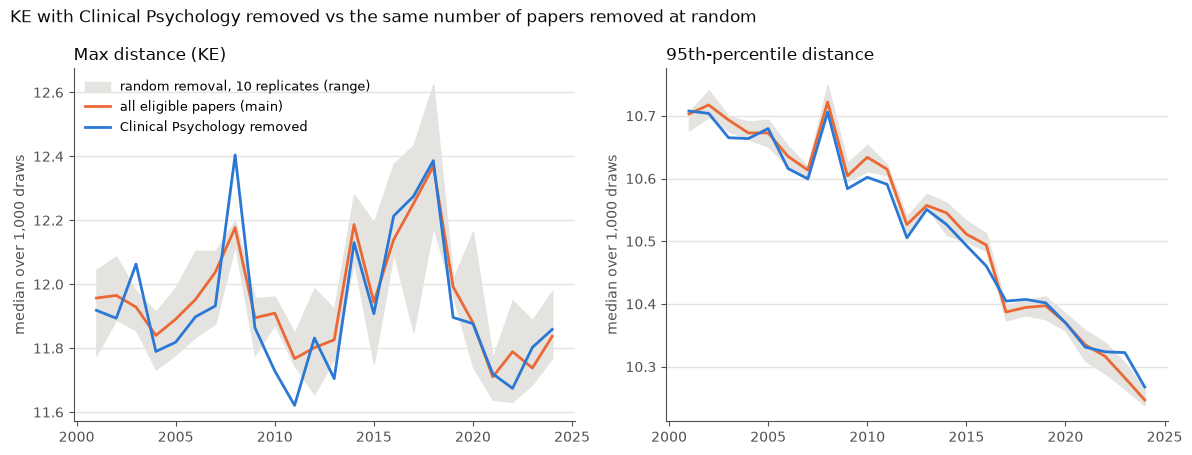

,max distance,95th percentile
main: mean level,11.949,10.527
random removal: mean level,11.960,10.526
Clinical removed: mean level,11.925,10.520
"Clinical removed minus random, mean over years (%)",-0.290,-0.057
years with Clinical removed outside the random range,6.000,14.000
"change 2001-03 to 2022-24, main (%)",-1.356,-3.949
"change, random removal (%, mean of 10)",-1.235,-3.894
"change, random removal (%, min)",-2.019,-4.030
"change, random removal (%, max)",-0.423,-3.805
"change, Clinical removed (%)",-1.503,-3.625


In [12]:
SANITY = Path("data/ke/psychology_field32/sanity")   # first run: about 11 minutes; later runs read the saved draws
summary_no_clinical = ke.summarize(ke.field_draws(EMBEDDINGS, no_clinical, YEARS,
                                                  output=SANITY / "ke_draws_no_clinical.parquet", l2=False)).set_index("year")
random_runs = [ke.summarize(ke.field_draws(EMBEDDINGS, ke.matched_random_subset(eligibility, sizes.to_dict(), r), YEARS,
                                           output=SANITY / f"ke_draws_random_{r}.parquet", l2=False)).set_index("year")
               for r in range(10)]
random_max = pd.concat({r: run["ke_max_median"] for r, run in enumerate(random_runs)}, axis=1)
random_p95 = pd.concat({r: run["ke_p95_median"] for r, run in enumerate(random_runs)}, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, column, randoms, title in ((axes[0], "ke_max_median", random_max, "Max distance (KE)"),
                                   (axes[1], "ke_p95_median", random_p95, "95th-percentile distance")):
    ax.fill_between(YEARS, randoms.min(axis=1), randoms.max(axis=1), color=GRID, label="random removal, 10 replicates (range)")
    ax.plot(YEARS, summary[column], color=ORANGE, lw=2, label="all eligible papers (main)")
    ax.plot(YEARS, summary_no_clinical[column], color=BLUE, lw=2, label="Clinical Psychology removed")
    ax.set_title(title, loc="left", color=INK)
    ax.set_ylabel("median over 1,000 draws", color=MUTED)
    style_axes(ax)
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
fig.suptitle("KE with Clinical Psychology removed vs the same number of papers removed at random",
             x=0.01, ha="left", color=INK)
fig.tight_layout()
fig.savefig(FIGURES / "field_ke_sanity_subfield.png", dpi=200, bbox_inches="tight")
plt.show()

rows = {}
for label, column, randoms in (("max distance", "ke_max_median", random_max), ("95th percentile", "ke_p95_median", random_p95)):
    change = lambda s: np.log(ke.window_mean(s, ke.LATE)) - np.log(ke.window_mean(s, ke.EARLY))
    random_change = randoms.apply(change)
    outside = (summary_no_clinical[column] < randoms.min(axis=1)) | (summary_no_clinical[column] > randoms.max(axis=1))
    rows[label] = {
        "main: mean level": summary[column].mean(),
        "random removal: mean level": randoms.mean(axis=1).mean(),
        "Clinical removed: mean level": summary_no_clinical[column].mean(),
        "Clinical removed minus random, mean over years (%)": 100 * (summary_no_clinical[column] / randoms.mean(axis=1) - 1).mean(),
        "years with Clinical removed outside the random range": int(outside.sum()),
        "change 2001-03 to 2022-24, main (%)": 100 * (np.exp(change(summary[column])) - 1),
        "change, random removal (%, mean of 10)": 100 * (np.exp(random_change.mean()) - 1),
        "change, random removal (%, min)": 100 * (np.exp(random_change.min()) - 1),
        "change, random removal (%, max)": 100 * (np.exp(random_change.max()) - 1),
        "change, Clinical removed (%)": 100 * (np.exp(change(summary_no_clinical[column])) - 1)}
sanity = pd.DataFrame(rows)
sanity.to_csv(TABLES / "field_ke_sanity_subfield.csv")
sanity.round(3)

**Random removal behaves as designed.** In all 24 years the main series lies inside the range of the 10 random-removal replicates, for both statistics. The replicates' change between 2001–03 and 2022–24 (−1.2% on average, −2.0% to −0.4% across replicates) brackets the main series' −1.4%. Removing 31% of the papers at random does not change KE beyond noise, so pool size is not what drives the measure.

**Removing the largest subfield barely changes KE either.** Without Clinical Psychology, median KE is on average 0.3% below random removal. It falls outside the random range in 6 of 24 years, in both directions (above in 2003 and 2008, below in 2010, 2011, 2013 and 2019), and its window change (−1.5%) lies inside the random range. The 95th percentile differs from random removal by less than 0.4% in every year. The diagnostic table shows why:

- Clinical papers sit closer to the centroid than papers from other subfields in every year (mean distance 9.18 vs 9.47 in 2001, 8.67 vs 9.00 in 2024).
- They make up 28–35% of the pool but at most 13.5% of each year's farthest 1%.
- They set the draw maximum in only 4% of draws on average.

KE is set by the edges of the space, and Clinical Psychology is not at the edge, so removing it takes away a third of the papers without taking away reach.

One small difference is systematic. Without Clinical, the 95th percentile falls by 3.6% between the windows rather than 3.9%, just outside the random range (−4.0% to −3.8%). Clinical papers moved toward the centre slightly faster than the rest (mean distance −5.5% vs −5.0% from 2001 to 2024), so a small part of the bulk's inward drift comes from Clinical Psychology itself.

**Why KE is sometimes higher without Clinical Psychology** (a diagnostic added after seeing the results). Removing a subfield changes two things that random removal does not.

- *The farthest papers become more concentrated.* A year's median KE is close to the distance of its k-th farthest paper, with k ≈ ln 2 × pool ÷ 1,000, because a paper enters a given draw with probability 1,000 ÷ pool. Without Clinical, k falls from about 6.6 to 4.6, and nearly all the farthest papers remain, so the median moves up the tail. Random removal drops a third of the farthest papers along with the rest and stays at the same point of the tail.
- *The centroid moves.* Without Clinical, the centroid shifts about 1 unit (about 8% of KE) away from the Clinical region, which brings some far papers closer and pushes others away.

The cell below estimates both effects from each year's pool, with the pool centroid standing in for the draw centroids.

In [13]:
def kth_farthest(distance, k):
    ranked = np.sort(distance)[::-1]
    return np.interp(k - 1, np.arange(len(ranked)), ranked)   # k may be fractional

title_of = pool.set_index("openalex_id")["title"]
topic_of = pd.read_parquet(POOL, columns=["openalex_id", "primary_topic"]).set_index("openalex_id")["primary_topic"]
rows, farthest_A = [], {}
for year in YEARS:
    ids = set(eligibility.loc[eligibility["ke_eligible"] & year_of.eq(year), "openalex_id"])
    X, kept_ids = ke.load_year(EMBEDDINGS, year, ids)
    is_clinical = subfield_of.loc[kept_ids].eq("Clinical Psychology").to_numpy()
    centre, centre_A = X.mean(axis=0), X[~is_clinical].mean(axis=0)
    shift = centre_A - centre                                    # how the centroid moves without Clinical
    distance = np.linalg.norm(X - centre, axis=1)
    distance_A = np.linalg.norm(X[~is_clinical] - centre_A, axis=1)
    k, k_A = np.log(2) * len(X) / ke.DRAW_SIZE, np.log(2) * (~is_clinical).sum() / ke.DRAW_SIZE
    main = kth_farthest(distance, k)                             # all papers
    same_centre = kth_farthest(distance[~is_clinical], k_A)      # without Clinical, centroid not moved
    moved = kth_farthest(distance_A, k_A)                        # without Clinical, own centroid
    top_A = np.argsort(distance_A)[::-1][:5]                     # the 5 papers farthest from the new centroid
    offsets = X[~is_clinical][top_A] - centre
    cosines = offsets @ shift / (np.linalg.norm(offsets, axis=1) * np.linalg.norm(shift))
    farthest_A[year] = pd.DataFrame({"cosine with the shift": cosines, "subfield": subfield_of.loc[kept_ids[~is_clinical][top_A]].to_numpy(),
                                     "topic": topic_of.loc[kept_ids[~is_clinical][top_A]].to_numpy(),
                                     "title": title_of.loc[kept_ids[~is_clinical][top_A]].to_numpy()})
    actual = summary_no_clinical.loc[year, "ke_max_median"]
    rows.append({"year": year, "k, all papers": k, "k, A": k_A,
                 "Clinical among the 10 farthest": int(is_clinical[np.argsort(distance)[::-1][:10]].sum()),
                 "centroid shift": np.linalg.norm(shift), "cosine, 5 farthest in A with the shift": cosines.mean(),
                 "tail effect (%)": 100 * (same_centre / main - 1), "centroid effect (%)": 100 * (moved / same_centre - 1),
                 "predicted A vs main (%)": 100 * (moved / main - 1),
                 "actual A vs main (%)": 100 * (actual / summary.loc[year, "ke_max_median"] - 1),
                 "A vs random range": ("above" if actual > random_max.loc[year].max() else
                                       "below" if actual < random_max.loc[year].min() else "")})
why = pd.DataFrame(rows).set_index("year")
print(f"Correlation of predicted and actual A vs main over the 24 years: "
      f"{why['predicted A vs main (%)'].corr(why['actual A vs main (%)']):.2f}")
print(f"Tail effect {why['tail effect (%)'].min():+.2f}% to {why['tail effect (%)'].max():+.2f}%; centroid effect mean "
      f"{why['centroid effect (%)'].mean():+.2f}%, positive only in {', '.join(map(str, why.index[why['centroid effect (%)'] > 0]))}")
for year in why.index[why["A vs random range"].eq("above")]:
    print(f"\n{year}: the papers farthest from the centroid without Clinical")
    print(farthest_A[year].head(3).round(2).to_string(index=False, max_colwidth=70))
why.round(2)

Correlation of predicted and actual A vs main over the 24 years: 0.96
Tail effect +0.15% to +2.45%; centroid effect mean -1.21%, positive only in 2003, 2008

2003: the papers farthest from the centroid without Clinical
 cosine with the shift                              subfield                                  topic                                                                  title
                 -0.15                     Social Psychology Neuroendocrine regulation and behavior   Myometrial microvascular endothelial cells express oxytocin receptor
                 -0.04 Experimental and Cognitive Psychology            Sleep and related disorders               Quality of sleep in patients with chronic kidney disease
                 -0.11                     Social Psychology Neuroendocrine regulation and behavior Oxytocin, But Not Oxytocin Receptor, is Regulated by Oestrogen Rece...

2008: the papers farthest from the centroid without Clinical
 cosine with the shift          sub

,"k, all papers","k, A",Clinical among the 10 farthest,centroid shift,"cosine, 5 farthest in A with the shift",tail effect (%),centroid effect (%),predicted A vs main (%),actual A vs main (%),A vs random range
year,,,,,,,,,,
2001,6.45,4.27,1,1.07,0.17,0.58,-1.23,-0.66,-0.32,
2002,6.48,4.30,0,1.04,0.13,1.09,-1.61,-0.54,-0.60,
2003,6.49,4.34,0,1.06,-0.13,0.31,0.80,1.11,1.13,above
2004,6.52,4.36,2,1.05,0.15,0.77,-1.16,-0.40,-0.42,
2005,6.55,4.47,1,0.99,0.12,0.66,-1.36,-0.71,-0.61,
2006,6.60,4.48,1,1.03,0.06,1.23,-1.62,-0.41,-0.45,
2007,6.60,4.50,0,1.02,0.14,0.90,-1.70,-0.81,-0.88,
2008,6.61,4.59,0,0.94,-0.15,0.30,1.70,2.00,1.87,above
2009,6.63,4.63,1,0.95,-0.10,0.46,-0.53,-0.07,-0.26,


The two effects pull in opposite directions. The tail effect raises KE in every year (+0.2% to +2.5%). The centroid effect lowers it in 22 of 24 years (mean −1.2%), because the papers that set KE without Clinical mostly lie in the direction the centroid moves (positive cosine), so they end up closer to it. On average the two cancel, which is why A stays close to random removal.

In 2003 and 2008 the farthest remaining papers lie on the other side (mean cosine −0.13 and −0.15), so the centroid moves away from them and both effects raise KE. Most of them are neuroendocrine physiology papers, on oxytocin in 2003 and on vasopressin and neurophysin in 2008, which OpenAlex files under Social Psychology through their topic, "Neuroendocrine regulation and behavior". In the four years below the random range, the centroid effect outweighs the tail effect. In 2010 and 2011 the tail effect is also small, because two and three of the ten farthest papers are Clinical, so removing them shortens the tail.

The approximation tracks the actual differences closely (correlation 0.96 over the 24 years), so the years outside the random range follow from how KE is built, as a maximum distance to each sample's own centroid. They do not show that Clinical Psychology makes the field narrower or broader. The same mechanism is why the theme analysis measures the composition effect rather than assuming its sign: a change in composition moves the centroid, and whether that raises or lowers KE depends on which side of it the edge papers lie.

**What the check shows and what it does not.** KE responds neither to pool size nor to the loss of a large block of papers near the centre, which is how a measure of reach should behave. The check cannot show that KE would register a real narrowing at the edge, because this subfield is not at the edge. A second check that removes a subfield far from the centre would test that.

## 8. Maps of the space: 2001 and 2024

Hao et al. (2026, Fig. 3b) show their result as a t-SNE map of 10,000 papers, half AI and half not, with arrows and circles marking each group's KE computed in the full embedding space. Their published code (github.com/tsinghua-fib-lab/AI-Impacts-Science) does not include the figure, so the t-SNE settings here are scikit-learn's defaults (perplexity 30, PCA initialization; seed 20261124). Instead of a separate batch of papers, each year is shown by one of its actual KE draws of 1,000 papers, the draw whose KE is closest to the year's median, so the farthest papers and KE values in both figures are the ones the measure uses. The real centroid of a draw is an average vector, not a paper, and t-SNE places only papers. On the t-SNE map, the dot at the centre of each circle is therefore the average map position of that year's papers, a stand-in for the centroid. In the aligned figure, the centre is the real centroid.

2001: draw 729, KE 11.96 (year median 11.96); farthest paper: Clinical Psychology, "Anorexia Nervosa with Ischemic Necrosis of the Segmental Ileum and Cecum."
2024: draw 498, KE 11.84 (year median 11.84); farthest paper: Experimental and Cognitive Psychology, "Research on Facial Expression Recognition Based on Improved VGG19"


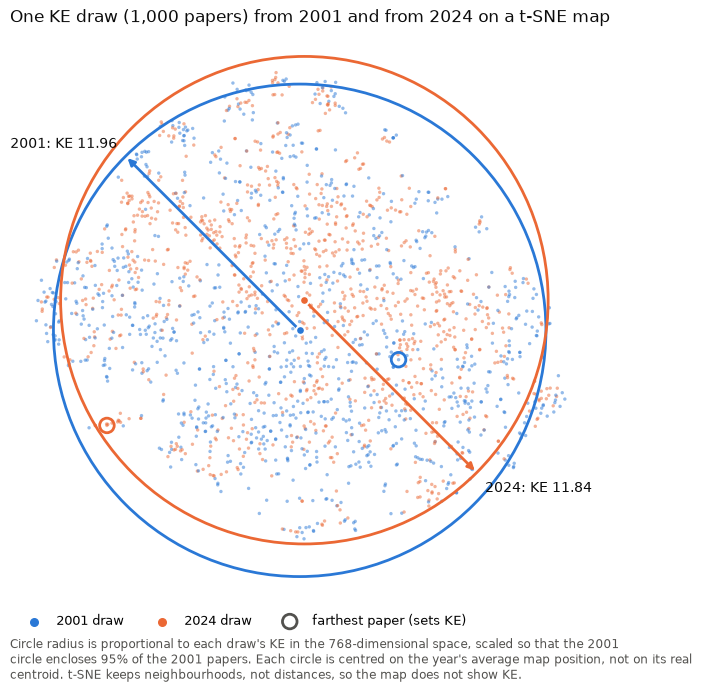

In [14]:
MAP_YEARS, MAP_SEED = (2001, 2024), 20261124
colors = dict(zip(MAP_YEARS, (BLUE, ORANGE)))
title_of = pool.set_index("openalex_id")["title"]
median_draw = {}
for year in MAP_YEARS:
    ids = set(eligibility.loc[eligibility["ke_eligible"] & eligibility["publication_year"].eq(year), "openalex_id"])
    X, kept_ids = ke.load_year(EMBEDDINGS, year, ids)
    year_draws = draws[draws["year"] == year].set_index("draw")["ke_max"]
    d = int((year_draws - year_draws.median()).abs().idxmin())    # the draw whose KE is closest to the year's median
    rows = ke.draw_indices(len(X), year)[d]                        # regenerates the draw's papers from the KE seed
    centred = X[rows] - X[rows].mean(axis=0)
    distance = np.linalg.norm(centred, axis=1)
    assert np.isclose(distance.max(), year_draws[d])               # same KE as the saved draw
    median_draw[year] = {"X": X[rows], "centred": centred, "distance": distance, "farthest": int(distance.argmax())}
    print(f"{year}: draw {d}, KE {distance.max():.2f} (year median {year_draws.median():.2f}); farthest paper: "
          f"{subfield_of[kept_ids[rows][distance.argmax()]]}, \"{title_of[kept_ids[rows][distance.argmax()]]}\"")

# Figure 1: t-SNE map in the style of Hao et al. (2026, Fig. 3b)
map_year = np.repeat(MAP_YEARS, ke.DRAW_SIZE)
xy = TSNE(n_components=2, random_state=MAP_SEED).fit_transform(np.vstack([median_draw[y]["X"] for y in MAP_YEARS]))
order = np.random.default_rng(MAP_SEED).permutation(len(xy))   # neither year is drawn on top of the other
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.scatter(xy[order, 0], xy[order, 1], s=6, c=[colors[y] for y in map_year[order]], alpha=0.5, linewidths=0)
centres = {year: xy[map_year == year].mean(axis=0) for year in MAP_YEARS}
ke_draw = {year: median_draw[year]["distance"].max() for year in MAP_YEARS}
# radius proportional to KE; the scale makes the 2001 circle enclose 95% of the 2001 papers on the map
scale = np.percentile(np.linalg.norm(xy[map_year == 2001] - centres[2001], axis=1), 95) / ke_draw[2001]
for year, angle in zip(MAP_YEARS, (135, -45)):
    radius, centre = scale * ke_draw[year], centres[year]
    tip = centre + radius * np.array([np.cos(np.radians(angle)), np.sin(np.radians(angle))])
    ax.add_patch(Circle(centre, radius, fill=False, color=colors[year], lw=2))
    ax.annotate("", tip, centre, arrowprops=dict(arrowstyle="-|>", color=colors[year], lw=2))
    left = angle > 90
    ax.annotate(f"{year}: KE {ke_draw[year]:.2f}", tip, xytext=(-6 if left else 6, 6 if left else -14),
                textcoords="offset points", ha="right" if left else "left", color=INK, fontsize=10)
    ax.scatter(*centre, color=colors[year], s=40, edgecolors="white", linewidths=1.5, zorder=3)
    ax.scatter(*xy[map_year == year][median_draw[year]["farthest"]], s=110, facecolors="none",
               edgecolors=colors[year], linewidths=2, zorder=4)
    ax.scatter([], [], s=30, color=colors[year], label=f"{year} draw")
ax.scatter([], [], s=110, facecolors="none", edgecolors=MUTED, linewidths=2, label="farthest paper (sets KE)")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.0), ncol=3, fontsize=9)
ax.set_aspect("equal")
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("One KE draw (1,000 papers) from 2001 and from 2024 on a t-SNE map", loc="left", color=INK)
ax.text(0, -0.06, "Circle radius is proportional to each draw's KE in the 768-dimensional space, scaled so that the 2001\n"
        "circle encloses 95% of the 2001 papers. Each circle is centred on the year's average map position, not on its real\n"
        "centroid. t-SNE keeps neighbourhoods, not distances, so the map does not show KE.",
        transform=ax.transAxes, va="top", color=MUTED, fontsize=8.5)
fig.savefig(FIGURES / "field_ke_tsne_2001_2024.png", dpi=200, bbox_inches="tight")
plt.show()

The two circles are almost the same size, because KE differs by only 1% between the two years. Both years' papers cover the same overall area, but some regions hold mostly 2001 papers and others mostly 2024 papers, a change in composition that the theme analysis will measure. The rings mark the paper that sets KE in each draw: a medical case report on anorexia nervosa in 2001 and a computer-vision paper on facial-expression recognition in 2024. The 2001 one sits inside the cloud rather than at its edge, because t-SNE keeps each paper's nearest neighbours close but distorts larger distances. This map shows which papers are similar, not how far each is from the centre.

**Centroids aligned.** To show distance, the next figure centres each draw on its own centroid, so both centroids sit at the same point. Each paper is plotted at its exact distance to its centroid in the 768-dimensional space. Only its direction is approximate, taken from the first two principal components of the two centred draws. The outer circles are therefore the exact KE of each draw, and the right panel shows the same distances as a histogram.

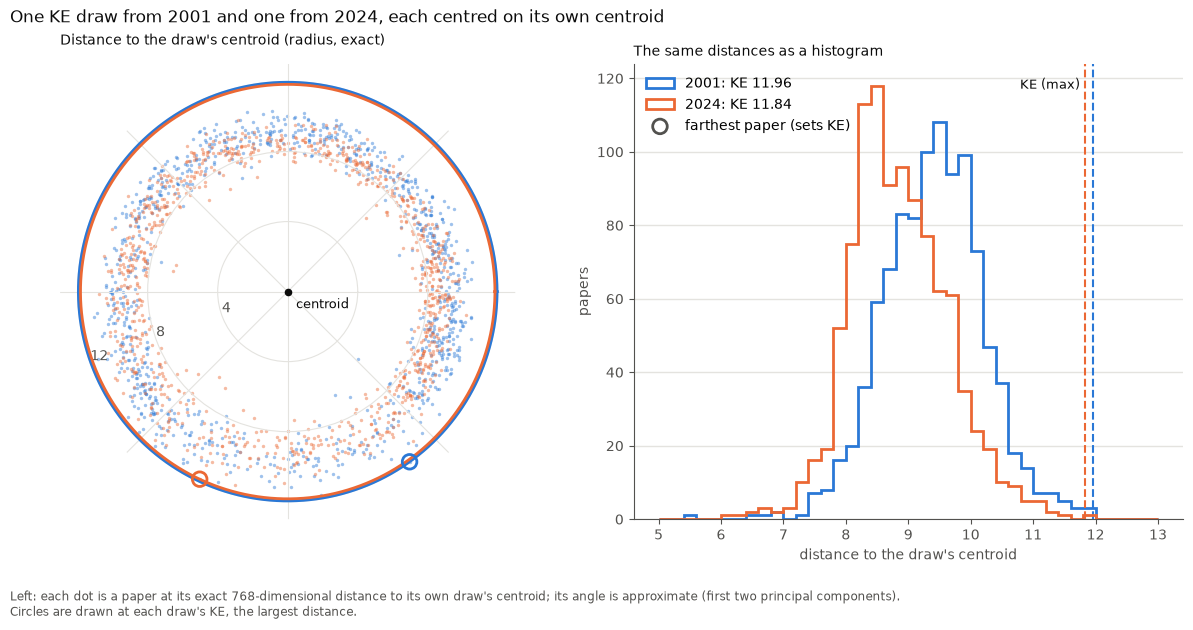

distance to the draw's centroid:
                  2001   2024  change
min               5.55   6.13  +10.4%
median            9.43   8.78   -6.9%
95th percentile  10.64  10.21   -4.1%
max (KE)         11.96  11.84   -1.0%


In [15]:
# Figure 2: centroids aligned. Radius = exact distance to the draw's own centroid; angle = direction in the first
# two principal components of the two centred draws together.
directions = np.linalg.svd(np.vstack([median_draw[y]["centred"] for y in MAP_YEARS]), full_matrices=False)[2][:2]
fig = plt.figure(figsize=(12, 5.8))
polar = fig.add_subplot(1, 2, 1, projection="polar")
hist = fig.add_subplot(1, 2, 2)
circle = np.linspace(0, 2 * np.pi, 400)
bins = np.arange(5, 13.01, 0.2)
for year in MAP_YEARS:
    sample = median_draw[year]
    projected = sample["centred"] @ directions.T
    angle = np.arctan2(projected[:, 1], projected[:, 0])
    polar.scatter(angle, sample["distance"], s=6, color=colors[year], alpha=0.45, linewidths=0)
    polar.plot(circle, np.full_like(circle, sample["distance"].max()), color=colors[year], lw=2)
    polar.scatter(angle[sample["farthest"]], sample["distance"][sample["farthest"]], s=110, facecolors="none",
                  edgecolors=colors[year], linewidths=2, zorder=4)
    hist.hist(sample["distance"], bins=bins, histtype="step", lw=2, color=colors[year],
              label=f"{year}: KE {sample['distance'].max():.2f}")
    hist.axvline(sample["distance"].max(), color=colors[year], lw=1.5, ls="--")
polar.scatter([0], [0], color=INK, s=20, zorder=4)
polar.annotate("centroid", (0, 0), xytext=(6, -12), textcoords="offset points", color=INK, fontsize=9)
polar.set_ylim(0, 13)
polar.set_yticks([4, 8, 12])
polar.set_rlabel_position(200)
polar.set_xticklabels([])
polar.tick_params(colors=MUTED)
polar.grid(color=GRID)
polar.spines["polar"].set_visible(False)
polar.set_title("Distance to the draw's centroid (radius, exact)", loc="left", color=INK, fontsize=10, pad=14)
hist.text(11.75, hist.get_ylim()[1] * 0.97, "KE (max)", ha="right", va="top", color=INK, fontsize=9)
hist.set_xlabel("distance to the draw's centroid", color=MUTED)
hist.set_ylabel("papers", color=MUTED)
hist.set_title("The same distances as a histogram", loc="left", color=INK, fontsize=10)
hist.scatter([], [], s=110, facecolors="none", edgecolors=MUTED, linewidths=2, label="farthest paper (sets KE)")
hist.legend(frameon=False, loc="upper left")
style_axes(hist)
fig.suptitle("One KE draw from 2001 and one from 2024, each centred on its own centroid", x=0.01, ha="left", color=INK)
fig.text(0.01, -0.02, "Left: each dot is a paper at its exact 768-dimensional distance to its own draw's centroid; its angle "
         "is approximate (first two principal components).\nCircles are drawn at each draw's KE, the largest distance.",
         color=MUTED, fontsize=8.5, va="top")
fig.tight_layout()
fig.savefig(FIGURES / "field_ke_aligned_2001_2024.png", dpi=200, bbox_inches="tight")
plt.show()

print("distance to the draw's centroid:")
print(pd.DataFrame({year: {"min": median_draw[year]["distance"].min(), "median": np.median(median_draw[year]["distance"]),
                           "95th percentile": np.percentile(median_draw[year]["distance"], 95),
                           "max (KE)": median_draw[year]["distance"].max()} for year in MAP_YEARS})
      .assign(change=lambda t: (t[2024] / t[2001] - 1).map("{:+.1%}".format)).round(2).to_string())

With distance shown exactly, two things stand out. First, no paper sits near its centroid. Every paper differs from the average of its draw in many of the 768 directions at once, so all distances fall between about 5.5 and 12, and KE is set by the few papers in the outer tail. Second, the bulk moved inward while the edge did not. The farther out in the distribution, the smaller the decline: the median distance fell by 6.9% between these two draws, the 95th percentile by 4.1%, and the maximum (KE) by 1.0%. This is the pattern of Section 6 seen in single draws. The typical paper sits closer to the centre in 2024, while the farthest papers reach about as far as in 2001.

## Summary

- **Output grew fivefold, KE did not.** Psychology published 29,631 journal articles in 2001 and 148,359 in 2024. Between 2001–03 and 2022–24 its median KE changed by −1.4%, a whole-period elasticity of −0.01: in fixed 1,000-paper samples, the field's semantic reach stayed where it was while output grew.
- **The bulk drew slightly inward.** The 95th-percentile distance fell by 3.9% (elasticity −0.03), steadily and without a link to year-to-year growth.
- **Year to year, no clear relationship.** The first-difference slope is −0.13 (95% CI −0.27 to 0.01) and depends on one episode. Without the *Journal of Vision* meeting abstracts that set most maxima in 2014–2018, it is −0.05 (−0.21 to 0.12).
- **The maximum is set by real papers at the field's edges**, about 50 different papers per year, none of them placeholder text.
- **Sanity check.** Removing 31% of the papers at random leaves KE unchanged. Removing Clinical Psychology, the largest subfield, changes it by 0.3% on average, because Clinical papers sit near the centre and rarely set the maximum. KE tracks the edges of the space, not where most papers are.

These are descriptions of one field's series. They do not say that growth causes or prevents breadth, and KE measures semantic dispersion in a fixed-size sample, not the amount of knowledge.

## What I learned and next steps

**What I learned**

- **Reach and output are decoupled at the field level.** A fivefold increase in output left KE flat. This matches Milojević's (2015) finding that cognitive extent does not track publication growth. On this measure, the additional papers fill the same semantic space rather than extending it, and the 95th percentile suggests the space is, if anything, filled slightly more densely near its centre.
- **Reading the extreme papers was the most informative step.** No summary statistic flagged the *Journal of Vision* meeting abstracts. They became visible only when I asked which papers set the maximum. A maximum-based measure is only as clean as its few most extreme documents, and the cleanliness of those documents can change from year to year with indexing practices.
- **KE measures the edges, not the mass.** Removing the largest subfield, a third of the field, left KE almost unchanged, because that subfield sits near the centre. A flat KE therefore says that the field did not reach new ground, not that its composition stayed the same. Composition is the job of the theme analysis in RQ2.
- **One series cannot estimate the growth relationship.** With growth between 4% and 10% in most years, the year-to-year slope depends on a couple of years. This is what the topic panel in the design is for: topics grew 1× to 20× over the same years, and year effects remove field-wide events such as the 2014–2018 meeting abstracts.

**Next steps**

1. Decide a general rule for meeting abstracts and conference proceedings, defined by source type, before the topic panel, and apply it to every analysis.
2. Pull and embed the topic-stratified sample (`src/openalex_topic_sample.py`), then estimate the topic panel.
3. Fit k-means on the KE-eligible papers and compute the fixed-mix decomposition.
4. Check whether abstract length relates to distance from the centroid. Median input length rose from 186 to 278 tokens over the period, so longer, more standardized abstracts could pull papers toward the centre, as well as changes in subject matter.
5. Repeat the sanity check with a large subfield far from the centre, such as Experimental and Cognitive Psychology, to test whether KE registers a real narrowing at the edge.
6. Optionally, draw a second independent pool for 2001 and 2024 to measure how much a year's KE depends on which 10,000 papers its pool contains.